# EfficientNet-B0와 ResNet18의 PCB 정상·불량 판정 비교

같은 PCB 사진에 대해 두 CNN의 판정을 비교한다. A는 DeepPCB, B는 DeepPCB + PKU, C는 DeepPCB + PKU + VisA PCB1~PCB4로 학습했다. 각 조합 안에서 데이터와 학습 조건을 맞추고 ImageNet 사전학습 모델을 바꿨다. **0 normal**, **1 defect**를 사용한다. 원본 한 장의 불량 점수는 해당 이미지의 모든 타일 중 가장 높은 불량 확률이다.

첫 두 비교표는 두 아키텍처의 저장된 예측을 읽는다. 이어지는 분할·학습 곡선·임계값·오분류 사례는 EfficientNet-B0 실험을 보여 준다.

In [1]:
from pathlib import Path
import sys

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as InlineImage, Markdown, display
from PIL import Image, ImageDraw

# deeppcb, src3 또는 PyCharm 프로젝트 루트에서 열 수 있다.
start = Path.cwd().resolve()
locations = [p / suffix for p in (start, *start.parents)
             for suffix in ("src3/config.json", "data_example/DeepPCB/deeppcb/src3/config.json")]
CONFIG = next((p for p in locations if p.is_file()), None)
if CONFIG is None:
    raise FileNotFoundError("deeppcb 폴더에서 열거나 CONFIG에 src3/config.json의 절대 경로를 지정하세요.")
PROJECT = CONFIG.parent.parent
sys.path.insert(0, str(PROJECT))
from src2.common import load_prepared, read_json, sha256
from src3.settings import load_config
from src3.comparison import paired_metrics

# 다른 실험을 보려면 여기에 그 설정 파일을 지정한다.
CONFIG = CONFIG.parent / "config.json"
DETAIL_MODE = "operating"   # "default"는 임계값 0.5
DETAIL_EXPERIMENT = "C"    # 출처별 아키텍처 비교와 EfficientNet-B0 사례를 볼 조합
ERROR_MODEL = DETAIL_EXPERIMENT
cfg = load_config(CONFIG)
output = Path(cfg["output_dir"])
prepared = output / "prepared"
run_root = output / "runs"
has_data = (prepared / "summary.json").is_file()
if has_data:
    _, originals, tiles, report = load_prepared(cfg)
    counts = pd.DataFrame(report["counts"])

models = [m for m in "ABC" if (run_root / m / "run.json").is_file()]
info = {m: read_json(run_root / m / "run.json") for m in models}
if len({v["protocol_id"] for v in info.values()}) > 1:
    raise ValueError("실험 조건이 다른 모델이 섞였습니다. 같은 설정으로 만든 결과를 선택하세요.")
if has_data and any(v["manifest_sha256"] != report["manifest_sha256"] for v in info.values()):
    raise ValueError("모델 학습 때와 현재 원본·타일 목록이 다릅니다.")
tested = [m for m in models if (run_root / m / "test/evaluation.json").is_file()]

plt.rcParams.update({"figure.dpi": 105, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
colors = {"A": "#315580", "B": "#b55a10", "C": "#007966"}
def table(frame):
    display(frame.style.format(precision=3, na_rep="—").hide(axis="index"))
def read_frame(path):
    return pd.read_csv(path, dtype={"board": str})
step_modules = {"prepare": "01_prepare", "train": "02_train", "evaluate": "03_evaluate"}
def command(step):
    return f'python -m src3.{step_modules[step]} --config "{CONFIG}"'
if not has_data:
    print("원본과 타일 목록을 먼저 만드세요.", command("prepare"))
if set(models) != set("ABC"):
    print("학습 결과가 필요한 실험", sorted(set("ABC") - set(models)), command("train"))
if set(tested) != set("ABC"):
    print("학습 완료 후 최종 평가", command("evaluate"))

In [18]:
"""Compare each src3 EfficientNet-B0 experiment on its training-source test data."""

from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# Run from src3 or its parent deeppcb folder.
src3_dir = Path.cwd()
if not (src3_dir / "artifacts" / "runs").exists():
    src3_dir = src3_dir / "src3"

experiment_sources = {
    "A": {"DeepPCB"},
    "B": {"DeepPCB", "PKU"},
    "C": {"DeepPCB", "PKU", "VisA"},
}

prediction_frames = []

for experiment, included_sources in experiment_sources.items():
    predictions_path = (
        src3_dir
        / "artifacts"
        / "runs"
        / experiment
        / "test"
        / "predictions.csv"
    )
    if not predictions_path.exists():
        raise FileNotFoundError(f"Prediction file not found: {predictions_path}")

    predictions = pd.read_csv(predictions_path)
    required_columns = {"source", "label", "prob_defect", "pred_default"}
    missing_columns = required_columns - set(predictions.columns)
    if missing_columns:
        raise ValueError(
            f"{predictions_path.name} is missing columns: {sorted(missing_columns)}"
        )

    # Evaluate each EfficientNet-B0 model only on test sources used for training.
    predictions = predictions[
        predictions["source"].astype(str).isin(included_sources)
    ].copy()
    predictions["experiment"] = experiment
    prediction_frames.append(predictions)

selected_predictions = pd.concat(prediction_frames, ignore_index=True)


def calculate_metrics(frame):
    actual = frame["label"].astype(int).to_numpy()
    predicted = frame["pred_default"].astype(int).to_numpy()
    probability = frame["prob_defect"].astype(float).to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()
    specificity = tn / (tn + fp) if tn + fp else np.nan
    false_positive_rate = fp / (tn + fp) if tn + fp else np.nan
    false_negative_rate = fn / (fn + tp) if fn + tp else np.nan
    has_both_classes = len(np.unique(actual)) == 2

    return {
        "test 이미지 수": len(frame),
        "정상 수": int((actual == 0).sum()),
        "불량 수": int((actual == 1).sum()),
        "정확도": accuracy_score(actual, predicted),
        "정밀도": precision_score(actual, predicted, zero_division=0),
        "재현율": recall_score(actual, predicted, zero_division=0),
        "특이도": specificity,
        "F1": f1_score(actual, predicted, zero_division=0),
        "ROC-AUC": roc_auc_score(actual, probability) if has_both_classes else np.nan,
        "PR-AUC": average_precision_score(actual, probability) if has_both_classes else np.nan,
        "TN": int(tn),
        "FP(오탐)": int(fp),
        "FN(미검출)": int(fn),
        "TP": int(tp),
        "정상 오탐률": false_positive_rate,
        "불량 미검출률": false_negative_rate,
    }


source_rows = []
for experiment, included_sources in experiment_sources.items():
    model_predictions = selected_predictions[
        selected_predictions["experiment"] == experiment
    ]
    for source in sorted(included_sources):
        source_predictions = model_predictions[
            model_predictions["source"].astype(str) == source
        ]
        if not source_predictions.empty:
            source_rows.append({
                "모델": f"{experiment} · EfficientNet-B0",
                "평가 출처": source,
                **calculate_metrics(source_predictions),
            })

source_results = pd.DataFrame(source_rows).sort_values(
    ["모델", "평가 출처"]
).reset_index(drop=True)
print("EfficientNet-B0 모델별·학습 포함 출처별 test 결과")
display(source_results.round(4))

pooled_rows = []
for experiment in experiment_sources:
    model_predictions = selected_predictions[
        selected_predictions["experiment"] == experiment
    ]
    if not model_predictions.empty:
        pooled_rows.append({
            "모델": f"{experiment} · EfficientNet-B0",
            "평가 출처": "학습 포함 출처 합산",
            **calculate_metrics(model_predictions),
        })

pooled_results = pd.DataFrame(pooled_rows)
print("EfficientNet-B0 모델별 학습 포함 출처 합산 test 결과")
display(pooled_results.round(4))


EfficientNet-B0 모델별·학습 포함 출처별 test 결과


,모델,평가 출처,test 이미지 수,정상 수,불량 수,정확도,정밀도,재현율,특이도,F1,ROC-AUC,PR-AUC,TN,FP(오탐),FN(미검출),TP,정상 오탐률,불량 미검출률
0,A · EfficientNet-B0,DeepPCB,432,216,216,0.8380,0.7992,0.9028,0.7731,0.8478,0.9337,0.9403,167,49,21,195,0.2269,0.0972
1,B · EfficientNet-B0,DeepPCB,432,216,216,0.9028,0.8372,1.0000,0.8056,0.9114,0.9928,0.9929,174,42,0,216,0.1944,0.0000
2,B · EfficientNet-B0,PKU,122,2,120,0.9836,0.9836,1.0000,0.0000,0.9917,0.4792,0.9862,0,2,0,120,1.0000,0.0000
3,C · EfficientNet-B0,DeepPCB,432,216,216,0.9653,0.9467,0.9861,0.9444,0.9660,0.9954,0.9953,204,12,3,213,0.0556,0.0139
4,C · EfficientNet-B0,PKU,122,2,120,0.9836,0.9836,1.0000,0.0000,0.9917,1.0000,1.0000,0,2,0,120,1.0000,0.0000
5,C · EfficientNet-B0,VisA,662,602,60,0.9879,0.9643,0.9000,0.9967,0.9310,0.9970,0.9770,600,2,6,54,0.0033,0.1000


EfficientNet-B0 모델별 학습 포함 출처 합산 test 결과


,모델,평가 출처,test 이미지 수,정상 수,불량 수,정확도,정밀도,재현율,특이도,F1,ROC-AUC,PR-AUC,TN,FP(오탐),FN(미검출),TP,정상 오탐률,불량 미검출률
0,A · EfficientNet-B0,학습 포함 출처 합산,432,216,216,0.8380,0.7992,0.9028,0.7731,0.8478,0.9337,0.9403,167,49,21,195,0.2269,0.0972
1,B · EfficientNet-B0,학습 포함 출처 합산,554,218,336,0.9206,0.8842,1.0000,0.7982,0.9385,0.9562,0.9682,174,44,0,336,0.2018,0.0000
2,C · EfficientNet-B0,학습 포함 출처 합산,1216,820,396,0.9794,0.9603,0.9773,0.9805,0.9687,0.9969,0.9929,804,16,9,387,0.0195,0.0227


## 같은 시험 원본에서 두 아키텍처 비교

같은 문자 조합끼리 읽는다. 원본·타일 목록과 학습 설정, 시험 원본 ID·정답·타일 수가 일치하는 쌍만 표시한다. **기본 0.5** 표는 두 모델에 같은 판정 기준을 적용한 결과다. **운영 임계값** 표에서는 각 모델이 공통 validation에서 선택한 기준을 적용한다. FPR은 정상 원본 중 불량으로 판정한 비율이며 FNR은 불량 원본 중 놓친 비율이다.

In [2]:
comparison, notes = paired_metrics(cfg)
for note in notes:
    print(note)
if any(not (Path(cfg["resnet_output_dir"]) / "runs" / m / "test/evaluation.json").is_file() for m in "ABC"):
    print("기본 경로의 ResNet18 결과 생성 순서: python -m src2.01_prepare → python -m src2.02_train → python -m src2.03_evaluate")
display_names = {"resnet18": "ResNet18", "efficientnet_b0": "EfficientNet-B0"}
pair_overall = comparison[comparison.scope == "all"].copy()
pair_overall["architecture"] = pair_overall.architecture.map(display_names)
if not pair_overall.empty:
    n = int(pair_overall.iloc[0]["n"])
    display(Markdown(f"각 아키텍처가 공통 시험 원본 **{n:,}장**을 판정한 결과다."))
    for mode, name in [("default", "기본 0.5"), ("operating", "검증에서 선택한 운영 임계값")]:
        display(Markdown(f"### {name}"))
        subset = pair_overall[pair_overall["mode"] == mode]
        table(subset[["experiment", "architecture", "threshold", "f1", "recall", "fpr",
                      "fp", "fn", "roc_auc", "pr_auc"]])
        scores = subset.pivot(index="experiment", columns="architecture", values="f1")
        gains = scores["EfficientNet-B0"] - scores["ResNet18"]
        print("F1 차이 (EfficientNet-B0 − ResNet18)", " / ".join(f"{exp} {d:+.3f}" for exp, d in gains.dropna().items()))

각 아키텍처가 공통 시험 원본 **1,216장**을 판정한 결과다.

### 기본 0.5

experiment,architecture,threshold,f1,recall,fpr,fp,fn,roc_auc,pr_auc
A,ResNet18,0.500,0.420,0.677,0.745,611,128,0.669,0.677
A,EfficientNet-B0,0.500,0.568,0.902,0.613,503,39,0.860,0.841
B,ResNet18,0.500,0.613,0.934,0.538,441,26,0.915,0.902
B,EfficientNet-B0,0.500,0.550,0.977,0.760,623,9,0.812,0.784
C,ResNet18,0.500,0.947,0.962,0.034,28,15,0.995,0.990
C,EfficientNet-B0,0.500,0.969,0.977,0.020,16,9,0.997,0.993


F1 차이 (EfficientNet-B0 − ResNet18) A +0.148 / B -0.063 / C +0.022


### 검증에서 선택한 운영 임계값

experiment,architecture,threshold,f1,recall,fpr,fp,fn,roc_auc,pr_auc
A,ResNet18,0.975,0.619,0.477,0.032,26,207,0.669,0.677
A,EfficientNet-B0,0.840,0.774,0.669,0.029,24,131,0.860,0.841
B,ResNet18,0.998,0.821,0.705,0.006,5,117,0.915,0.902
B,EfficientNet-B0,0.977,0.622,0.455,0.004,3,216,0.812,0.784
C,ResNet18,0.949,0.903,0.831,0.005,4,67,0.995,0.990
C,EfficientNet-B0,0.805,0.960,0.942,0.010,8,23,0.997,0.993


F1 차이 (EfficientNet-B0 − ResNet18) A +0.155 / B -0.199 / C +0.057


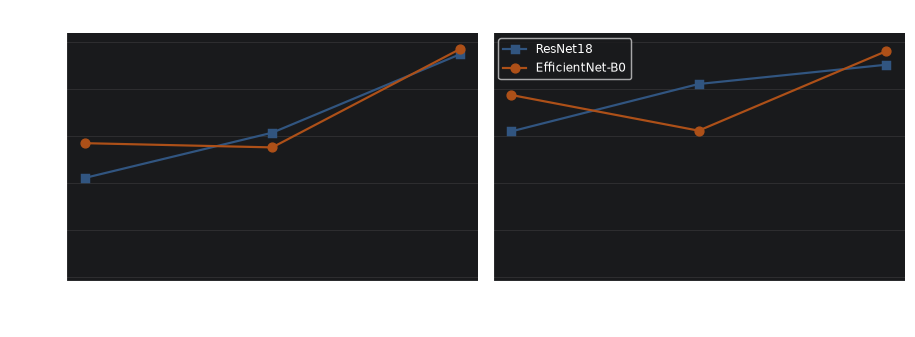

In [3]:
if not pair_overall.empty:
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1), sharey=True, layout="constrained")
    for ax, mode, title in zip(axes, ["default", "operating"], ["Threshold 0.5", "Validation-selected thresholds"]):
        view = pair_overall[pair_overall["mode"] == mode]
        for name, color, marker in [("ResNet18", "#315580", "s"), ("EfficientNet-B0", "#ad5018", "o")]:
            scores = view[view.architecture == name].set_index("experiment").f1.reindex(list("ABC"))
            ax.plot(range(3), scores, label=name, color=color, marker=marker)
        ax.set(xticks=range(3), xticklabels=list("ABC"), xlabel="Training experiment",
               title=title, ylim=(-0.02, 1.04))
        ax.grid(axis="y", alpha=0.18)
    axes[0].set_ylabel("F1 on test originals")
    axes[1].legend(fontsize=8)
    plt.show()

### 출처별 오탐과 미검출

설정 셀의 `DETAIL_EXPERIMENT`로 A/B/C를, `DETAIL_MODE`로 임계값을 선택한다. Δ recall과 Δ FPR의 단위는 퍼센트포인트다. PKU 정상 원본과 각 VisA PCB의 불량 원본 수를 분모와 함께 확인한다.

In [4]:
selected = comparison[(comparison.experiment == DETAIL_EXPERIMENT) & (comparison["mode"] == DETAIL_MODE)]
if not selected.empty:
    keys = ["scope", "n_normal", "n_defect"]
    paired = selected.pivot(index=keys, columns="architecture", values=["recall", "fpr", "fp", "fn"])
    view = pd.DataFrame(index=paired.index)
    for metric in ("recall", "fpr"):
        view[f"ResNet18 {metric}"] = paired[metric]["resnet18"]
        view[f"B0 {metric}"] = paired[metric]["efficientnet_b0"]
        view[f"Δ {metric} (pp)"] = 100 * (view[f"B0 {metric}"] - view[f"ResNet18 {metric}"])
    view["Δ FP (images)"] = paired["fp"]["efficientnet_b0"] - paired["fp"]["resnet18"]
    view["Δ FN (images)"] = paired["fn"]["efficientnet_b0"] - paired["fn"]["resnet18"]
    print("학습 조합", DETAIL_EXPERIMENT, "임계값 모드", DETAIL_MODE)
    table(view.reset_index())
    for r in selected[selected.scope == "all"].itertuples():
        print(f"{display_names[r.architecture]} · 불량 {r.n_defect}장 중 {r.fn}장 미검출, 정상 {r.n_normal}장 중 {r.fp}장 오탐")

학습 조합 C 임계값 모드 operating


scope,n_normal,n_defect,ResNet18 recall,B0 recall,Δ recall (pp),ResNet18 fpr,B0 fpr,Δ fpr (pp),Δ FP (images),Δ FN (images)
DeepPCB,216,216,0.907,0.981,7.407,0.009,0.028,1.852,4.000,-16.000
PKU,2,120,0.892,1.000,10.833,0.500,1.000,50.000,1.000,-13.000
VisA,602,60,0.433,0.683,25.000,0.002,0.000,-0.166,-1.000,-15.000
VisA/pcb1,150,15,0.333,0.733,40.000,0.000,0.000,0.000,0.000,-6.000
VisA/pcb2,150,15,0.733,0.733,0.000,0.007,0.000,-0.667,-1.000,0.000
VisA/pcb3,151,15,0.333,0.533,20.000,0.000,0.000,0.000,0.000,-3.000
VisA/pcb4,151,15,0.333,0.733,40.000,0.000,0.000,0.000,0.000,-6.000
all,820,396,0.831,0.942,11.111,0.005,0.010,0.488,4.000,-44.000


ResNet18 · 불량 396장 중 67장 미검출, 정상 820장 중 4장 오탐
EfficientNet-B0 · 불량 396장 중 23장 미검출, 정상 820장 중 8장 오탐


## EfficientNet-B0 실행 결과

In [5]:
if has_data:
    display(Markdown(f"원본 **{len(originals):,}장**에서 창 **{len(tiles):,}개**를 만들었다. "
                     f"부분 겹침으로 타일 지도학습에서 제외한 창은 **{(tiles.label == -1).sum():,}개**다."))
if tested:
    test_reports = {m: read_json(run_root / m / "test/evaluation.json") for m in tested}
    if len({r["test_ids_sha256"] for r in test_reports.values()}) != 1:
        raise ValueError("모델 간 test 원본 ID가 다릅니다.")
    for m, r in test_reports.items():
        if any(sha256(run_root / m / "test" / name) != digest for name, digest in r["files"].items()):
            raise ValueError(f"{m}의 저장된 시험 결과가 변경되었습니다.")
    final = pd.concat([read_frame(run_root / m / "test/metrics.csv").assign(model=m) for m in tested],
                      ignore_index=True)
    overall = final[final.scope == "all"]
    compact = overall[overall["mode"] == DETAIL_MODE]
    display(Markdown(f"공통 test **{int(compact.iloc[0]['n']):,}장**, "
                     f"아래 표는 **{DETAIL_MODE}** 임계값의 원본 이미지 결과다."))
    table(compact[["model", "threshold", "tp", "fn", "fp", "recall", "fpr", "pr_auc"]])
    if "C" in tested:
        c = overall[overall.model == "C"].set_index("mode")
        print(f"C에서 기본 0.5의 오탐 {c.loc['default', 'fp']}장·미검출 {c.loc['default', 'fn']}장, "
              f"검증에서 고른 운영 임계값의 오탐 {c.loc['operating', 'fp']}장·미검출 {c.loc['operating', 'fn']}장.")
else:
    print("확정된 시험 지표가 없습니다.", command("evaluate"))

원본 **8,119장**에서 창 **46,486개**를 만들었다. 부분 겹침으로 타일 지도학습에서 제외한 창은 **915개**다.

공통 test **1,216장**, 아래 표는 **operating** 임계값의 원본 이미지 결과다.

model,threshold,tp,fn,fp,recall,fpr,pr_auc
A,0.840,265,131,24,0.669,0.029,0.841
B,0.977,180,216,3,0.455,0.004,0.784
C,0.805,373,23,8,0.942,0.010,0.993


C에서 기본 0.5의 오탐 16장·미검출 9장, 검증에서 고른 운영 임계값의 오탐 8장·미검출 23장.


## 원본 데이터와 라벨

DeepPCB 검사 이미지는 TXT에 결함 박스가 있으면 불량이고 정상 템플릿은 정상이다. PKU의 이미지와 Pascal VOC XML은 상대 경로와 파일명, 원본 크기로 연결한다. VisA는 Normal과 Anomaly 폴더를 따르며, 이상 마스크의 0이 아닌 값을 전경으로 읽는다. 이 작업 공간에서 PKU XML 원본은 `out_data/PCB_DATASET`에 있고, 비슷한 이름의 `PCB-Defect An Annotated Dataset` 폴더는 별도 배포본이다.

[DeepPCB 공식 라벨](https://github.com/tangsanli5201/DeepPCB) · [PKU-Market-PCB](https://robotics.pkusz.edu.cn/resources/dataset/) · [VisA 원본 구조](https://github.com/amazon-science/spot-diff)

In [6]:
table(pd.DataFrame([{"source": s, "root": p, "directory_exists": Path(p).is_dir()}
                    for s, p in cfg["paths"].items()]))
if has_data:
    sample = originals.groupby(["source", "role"], sort=False).head(1).copy()
    sample["files_present"] = [
        (Path(cfg["paths"][r.source]) / r.path).is_file()
        and (not r.annotation or (Path(cfg["paths"][r.source]) / r.annotation).is_file())
        for r in sample.itertuples()]
    table(sample[["source", "role", "path", "annotation", "width", "height", "files_present"]])

source,root,directory_exists
DeepPCB,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\data,True
PKU,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\out_data\PCB_DATASET,True
VisA,C:\Users\Win11Pro\Documents\18_kdt_팀프로젝트_5차~1123\data_example\DeepPCB\deeppcb\out_data,True


source,role,path,annotation,width,height,files_present
DeepPCB,template,group00041/00041/00041000_temp.jpg,,640,640,True
DeepPCB,tested,group00041/00041/00041000_test.jpg,group00041/00041_not/00041000.txt,640,640,True
PKU,template,PCB_USED/01.JPG,,3034,1586,True
PKU,tested,images/Missing_hole/01_missing_hole_01.jpg,Annotations/Missing_hole/01_missing_hole_01.xml,3034,1586,True
VisA,anomaly,pcb1/Data/Images/Anomaly/000.JPG,pcb1/Data/Masks/Anomaly/000.png,1404,1070,True
VisA,normal,pcb1/Data/Images/Normal/0000.JPG,,1404,1070,True


In [7]:
if has_data:
    totals = counts.groupby("source", as_index=False)[
        ["original_normal", "original_defect", "all_tiles", "tile_normal", "tile_defect", "tile_excluded"]].sum()
    table(totals)
    visa = originals[originals.source == "VisA"]
    if not visa.empty:
        table(visa.groupby(["board", "label"]).size().unstack(fill_value=0)
              .rename(columns={0: "normal originals", 1: "defect originals"}).reset_index())
    print("공식 목록 밖의 파일과 기존 증강본", report["omitted"])

source,original_normal,original_defect,all_tiles,tile_normal,tile_defect,tile_excluded
DeepPCB,1500,1500,3000,1500,1500,0
PKU,10,693,16990,11856,4374,760
VisA,4016,400,26496,25156,1185,155


board,normal originals,defect originals
pcb1,1004,100
pcb2,1001,100
pcb3,1006,100
pcb4,1005,100


공식 목록 밖의 파일과 기존 증강본 {'DeepPCB_unlisted_images': ['group90100/90100/90100034_temp.jpg'], 'PKU_rotation_images': 693}


## 보드 그룹, 분할과 누수 검사

원본을 먼저 분할하고 그 안에서 타일을 만든다. 같은 DeepPCB 그룹과 PKU 보드 번호는 정상·불량을 함께 이동한다. VisA는 각 PCB 종류의 클래스별로 원본 ID를 배정한다. 증강은 학습 배치를 읽은 뒤 적용한다. 아래 그룹 수와 이미지 수는 실제 분할의 크기다.

In [8]:
if has_data:
    print("Seed", report["settings"]["seed"], "목표 train / validation / test", report["settings"]["split_fractions"])
    table(counts[["source", "split", "groups", "original_normal", "original_defect", "all_tiles",
                  "kept_tiles", "tile_excluded", "originals_with_kept_tiles", "defect_originals_without_positive_tile"]])
    boards = originals[originals.source.isin(["DeepPCB", "PKU"])]
    groups = boards.groupby(["source", "split"]).board.agg(lambda x: ", ".join(sorted(set(x))))
    table(groups.rename("board IDs").reset_index())
    if report["groups_missing_split"]:
        print("그룹 수 제약으로 비어 있는 구간", report["groups_missing_split"])
    print("같은 분할 내 바이트 중복 추가 파일", report["leakage"]["repeated_image_files_within_split"])
    table(pd.DataFrame(report["leakage"]["violations"].items(), columns=["누수·무결성 검사", "위반 건수"]))

Seed 42 목표 train / validation / test [0.7, 0.15, 0.15]


source,split,groups,original_normal,original_defect,all_tiles,kept_tiles,tile_excluded,originals_with_kept_tiles,defect_originals_without_positive_tile
DeepPCB,train,7,1004,1004,2008,2008,0,2008,0
DeepPCB,validation,3,280,280,560,560,0,560,0
DeepPCB,test,1,216,216,432,432,0,432,0
PKU,train,7,7,453,10676,10161,515,460,0
PKU,validation,1,1,120,3630,3527,103,121,0
PKU,test,2,2,120,2684,2542,142,122,0
VisA,train,3091,2811,280,18546,18444,102,3091,0
VisA,validation,663,603,60,3978,3951,27,663,0
VisA,test,662,602,60,3972,3946,26,662,0


source,split,board IDs
DeepPCB,test,group13000
DeepPCB,train,"group00041, group12300, group20085, group44000, group50600, group77000, group90100"
DeepPCB,validation,"group12000, group12100, group92000"
PKU,test,"05, 09"
PKU,train,"01, 06, 07, 08, 10, 11, 12"
PKU,validation,04


같은 분할 내 바이트 중복 추가 파일 2


누수·무결성 검사,위반 건수
image_id_in_multiple_splits,0
group_id_in_multiple_splits,0
sha256_in_multiple_splits,0
same_bytes_conflicting_labels,0
duplicate_original_id,0
duplicate_tile_id,0
repeated_tile_in_original,0
tile_parent_split_mismatch,0
originals_without_tiles,0


## 타일이 실제 결함을 포함하는지 확인

왼쪽 그림의 청록색 선은 원본에서 자른 창이고, 분홍색은 정답 박스 또는 마스크다. 가운데는 모델이 볼 타일의 원래 RGB 영상이며 오른쪽은 정답을 겹친 타일이다. 각 결함의 전체 박스 면적 또는 마스크 연결 성분 픽셀 수를 분모로 쓴다. 여러 결함 중 가장 큰 포함 비율을 기록한다. 겹침이 0이면 정상, 양수이면서 기준에 못 미치면 제외한다. 아래 예시는 학습 원본에서 골랐다.

타일 정책 {'size': 640, 'overlap': 128, 'min_defect_coverage': 0.5}


source,example,image_id,tile_id,overlap_px,region_px,overlap_fraction
DeepPCB,normal,DeepPCB/group00041/00041/00041000_temp.jpg,0,0,0,0.000
DeepPCB,defect,DeepPCB/group00041/00041/00041000_test.jpg,1,840,840,1.000
PKU,normal,PKU/PCB_USED/01.JPG,3000,0,0,0.000
PKU,defect,PKU/images/Missing_hole/01_missing_hole_01.jpg,3242,3276,4221,0.776
PKU,excluded,PKU/images/Missing_hole/01_missing_hole_02.jpg,3267,1265,2970,0.426
VisA,normal,VisA/pcb1/Data/Images/Normal/0000.JPG,20590,0,0,0.000
VisA,defect,VisA/pcb1/Data/Images/Anomaly/000.JPG,19993,1524,1524,1.000
VisA,excluded,VisA/pcb1/Data/Images/Anomaly/009.JPG,20047,387,4769,0.081


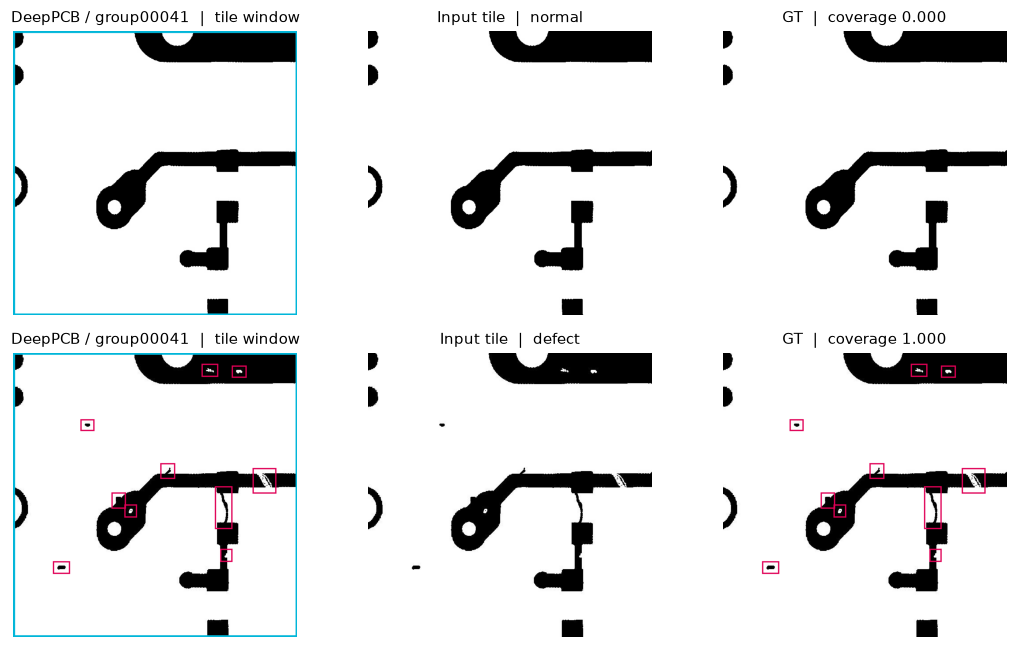

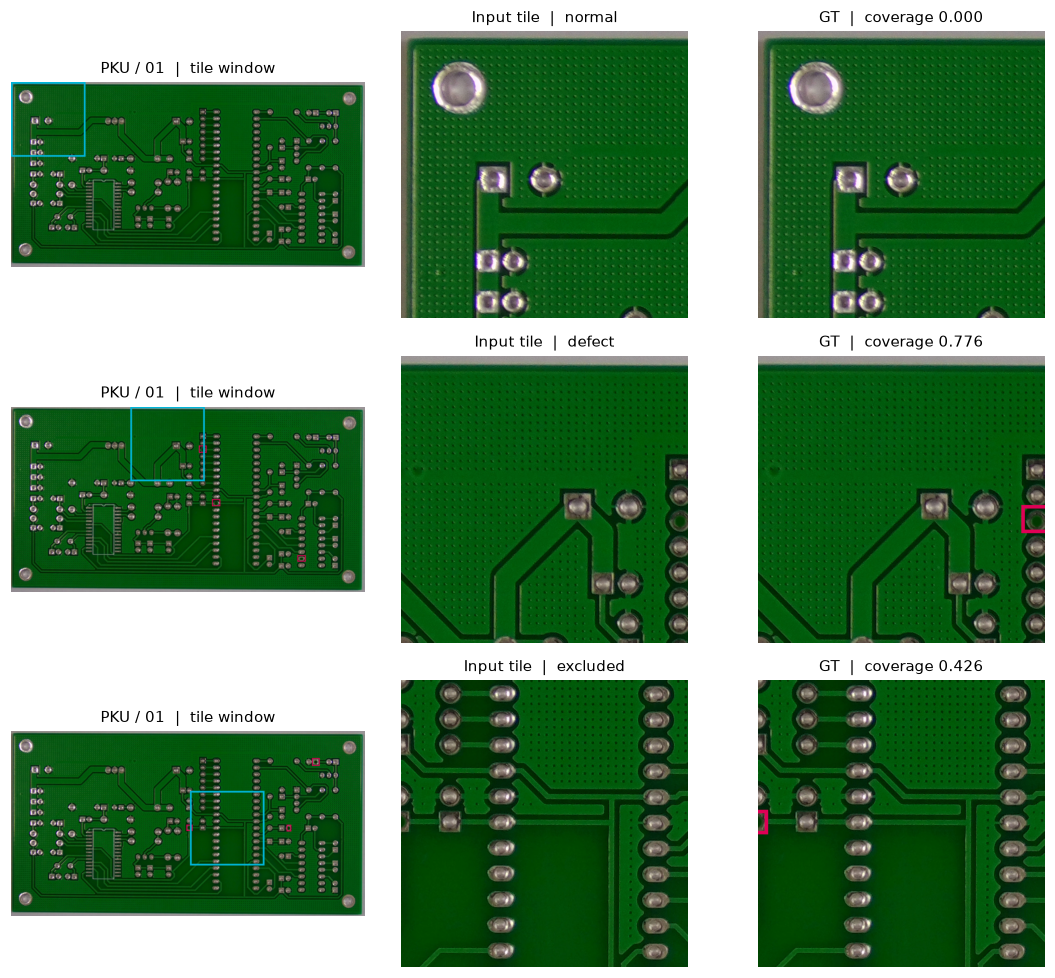

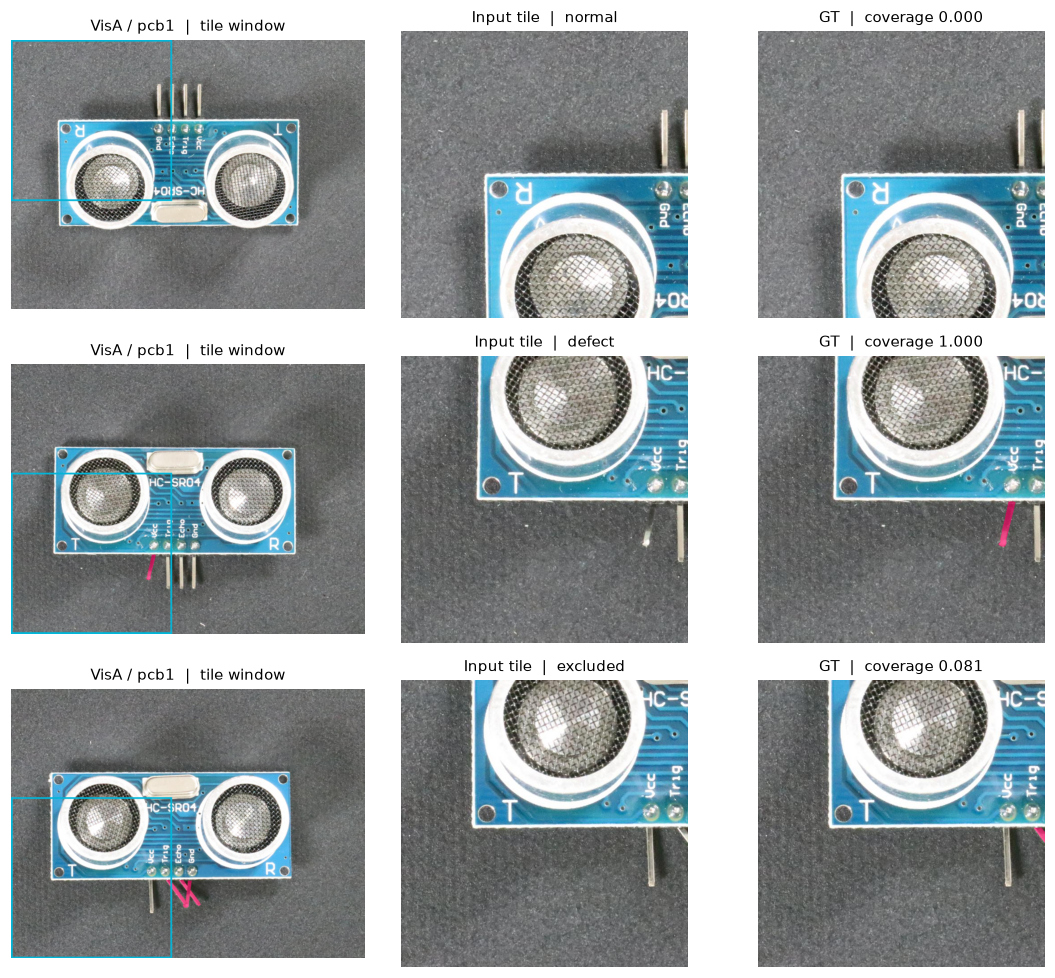

In [9]:
if has_data:
    print("타일 정책", report["settings"]["tiling"])
    examples = read_frame(prepared / "preview_examples.csv")
    table(examples[["source", "example", "image_id", "tile_id", "overlap_px", "region_px", "overlap_fraction"]])
    for source in cfg["sources"]:
        sample = prepared / "previews" / f"{source}.png"
        if sample.is_file():
            display(InlineImage(filename=str(sample), width=760))

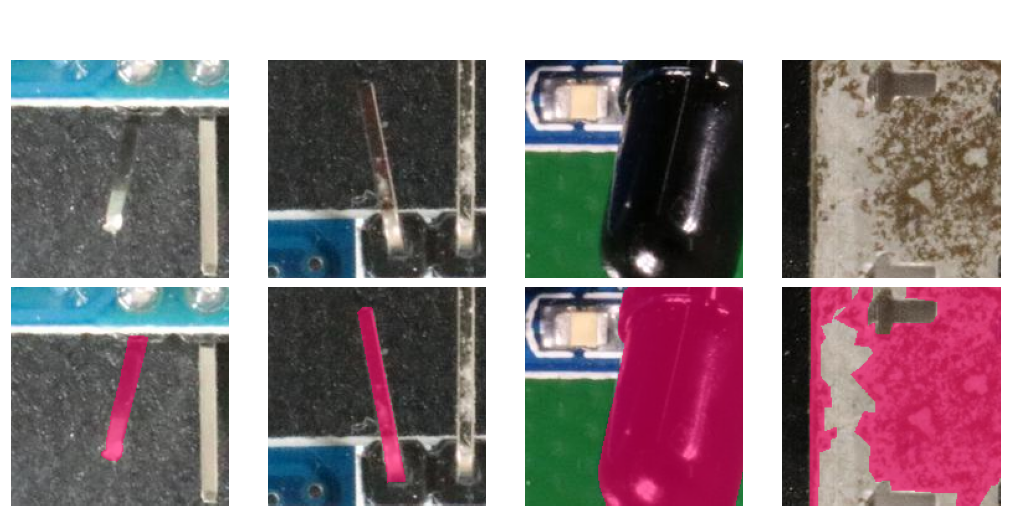

In [10]:
if has_data and "VisA" in cfg["sources"]:
    from src2.tiles import read_mask
    visa_root = Path(cfg["paths"]["VisA"])
    sample = originals[(originals.source == "VisA") & (originals.split == "train") &
                       (originals.label == 1)].groupby("board").head(1)
    available = [r for r in sample.itertuples()
                 if (visa_root / r.path).is_file() and (visa_root / r.annotation).is_file()]
    if available:
        fig, axes = plt.subplots(2, len(available), figsize=(2.45 * len(available), 4.8),
                                 squeeze=False, layout="constrained")
        for j, r in enumerate(available):
            with Image.open(visa_root / r.path) as raw:
                photo = raw.convert("RGB")
            mask = read_mask(visa_root / r.annotation, photo.size)
            y, x = np.argwhere(mask)[int(mask.sum()) // 2]
            crop = (max(0, x-88), max(0, y-88), min(photo.width, x+88), min(photo.height, y+88))
            marked = photo.copy()
            marked.paste(Image.new("RGB", photo.size, "#ff0066"), mask=Image.fromarray(mask.astype("uint8") * 155))
            for ax, view in zip(axes[:, j], [photo.crop(crop), marked.crop(crop)]):
                ax.imshow(view)
                ax.axis("off")
            axes[0, j].set_title(f"{r.board} / {Path(r.path).stem}")
        fig.suptitle("VisA training images   |   raw detail (top), foreground mask (bottom)")
        plt.show()
    else:
        print("VisA의 원본 이미지와 마스크 경로를 확인하세요.")

## EfficientNet-B0 학습 곡선과 최적 체크포인트

A는 DeepPCB, B는 DeepPCB와 PKU, C는 세 출처를 모두 사용해 가중치를 갱신한다. 모든 모델이 같은 validation 원본을 보고 체크포인트와 운영 임계값을 고른다. 학습 loss는 선택한 불균형 보정 방식의 타일 손실이다. 검증은 타일 손실과 원본당 손실을 각각 기록하며, **검증 원본 로그 손실이 가장 낮은 epoch**를 선택한다.

model,train sources,normal tiles,defect tiles,best epoch,val originals,best val image loss
A,DeepPCB,1004,1004,1,1344,0.613
B,DeepPCB + PKU,8189,3980,1,1344,0.845
C,DeepPCB + PKU + VisA,25805,4808,2,1344,0.172


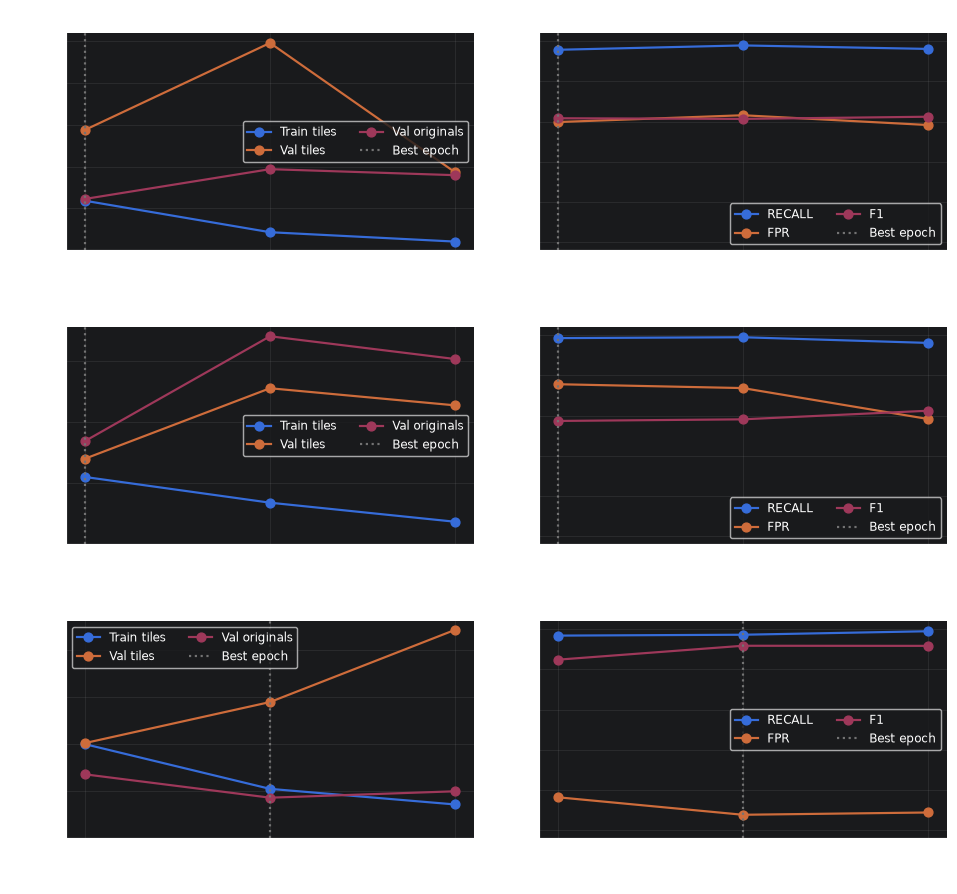

In [11]:
if models:
    rows = []
    fig, axes = plt.subplots(len(models), 2, figsize=(9, 2.8 * len(models)), squeeze=False,
                             layout="constrained")
    for m, (left, right) in zip(models, axes):
        history = read_frame(run_root / m / "history.csv")
        r = info[m]
        rows.append({"model": m, "train sources": " + ".join(r["train_sources"]),
                     "normal tiles": r["train_tiles"]["normal"], "defect tiles": r["train_tiles"]["defect"],
                     "best epoch": r["best_epoch"], "val originals": r["validation_originals"],
                     "best val image loss": r["best_validation_image_log_loss"]})
        series = [("train_loss", "Train tiles"), ("val_tile_loss", "Val tiles"),
                  ("val_image_loss", "Val originals")]
        for field, name in series:
            left.plot(history.epoch, history[field], marker="o", label=name)
        for field in ("recall", "fpr", "f1"):
            right.plot(history.epoch, history["val_" + field], marker="o", label=field.upper())
        left.set(title=f"{m}   Cross-entropy", ylabel="Loss", ylim=(0, None))
        right.set(title=f"{m}   Validation originals at 0.5", ylabel="Fraction", ylim=(-0.04, 1.04))
        for ax in (left, right):
            ax.axvline(r["best_epoch"], color="0.45", linestyle=":", label="Best epoch")
            ax.set(xlabel="Epoch", xticks=history.epoch if len(history) <= 12 else history.epoch.iloc[::len(history)//8])
            ax.grid(alpha=0.15)
            ax.legend(fontsize=8, ncol=2)
    table(pd.DataFrame(rows))
    plt.show()
else:
    print(command("train"))

### Validation에서 결정한 운영 임계값

각 후보에서 불량 recall과 정상 FPR을 계산한다. 정상 FPR 상한 안에서 recall을 최대화하며, 두 목표의 동시 충족 여부를 함께 기록한다. 목표를 충족하지 못한 경우에도 실제 선택 근거와 해당 지표를 표시한다.

A 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 False · Recall target infeasible under the FPR cap. Maximize recall within the cap.
B 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 False · Recall target infeasible under the FPR cap. Maximize recall within the cap.
C 목표 {'min_recall': 0.9, 'max_fpr': 0.05} 동시 충족 True · Both targets met. Maximize recall, then minimize FPR, then choose closest to 0.5.


model,mode,threshold,n_normal,n_defect,precision,recall,fpr,f1
A,default,0.500,884,460,0.455,0.957,0.597,0.616
A,operating,0.840,884,460,0.869,0.633,0.050,0.732
B,default,0.500,884,460,0.404,0.985,0.756,0.573
B,operating,0.977,884,460,0.859,0.543,0.046,0.666
C,default,0.500,884,460,0.868,0.972,0.077,0.917
C,operating,0.805,884,460,0.909,0.957,0.050,0.932


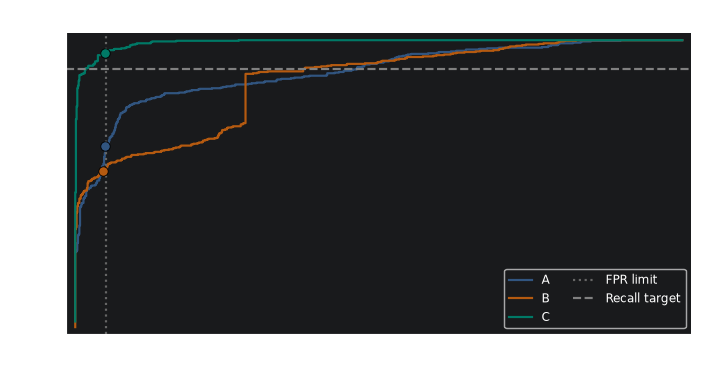

In [12]:
if models:
    rows = []
    for m in models:
        rule = read_json(run_root / m / "threshold.json")
        v = read_frame(run_root / m / "validation/metrics.csv")
        for row in v[v.scope == "all"].itertuples():
            rows.append({"model": m, "mode": row.mode, "threshold": row.threshold,
                         "n_normal": row.n_normal, "n_defect": row.n_defect,
                         "precision": row.precision, "recall": row.recall, "fpr": row.fpr, "f1": row.f1})
        print(m, "목표", rule["policy"], "동시 충족", rule["targets_met"], "·", rule["reason"])
    table(pd.DataFrame(rows))
    fig, ax = plt.subplots(figsize=(6.6, 3.6), layout="constrained")
    for m in models:
        curve = read_frame(run_root / m / "validation/threshold_curve.csv")
        r = read_json(run_root / m / "threshold.json")
        ax.step(curve.fpr, curve.recall, where="post", color=colors[m], label=m)
        if r["validation"]["fpr"] is not None and r["validation"]["recall"] is not None:
            ax.scatter(r["validation"]["fpr"], r["validation"]["recall"], s=42, color=colors[m],
                       edgecolor="black", linewidth=0.6, zorder=4)
    ax.axvline(cfg["threshold"]["max_fpr"], color="0.4", ls=":", label="FPR limit")
    ax.axhline(cfg["threshold"]["min_recall"], color="0.5", ls="--", label="Recall target")
    ax.set(xlim=(-0.015, 1.015), ylim=(-0.025, 1.025), xlabel="False-positive rate",
           ylabel="Defect recall", title="Validation originals   |   dots mark selected thresholds")
    ax.legend(ncol=2, fontsize=8)
    plt.show()

## EfficientNet-B0의 공통 test 원본 평가

창을 전부 추론한 후 가장 높은 불량 확률을 원본의 점수로 사용한다. 부분 겹침으로 학습에서 제외한 창도 여기에는 들어간다. 기본 0.5와 저장된 운영 임계값은 같은 예측으로 평가한다. 표의 **—**는 정의할 수 없는 값이다. 한 클래스만 있는 구간의 ROC-AUC·PR-AUC와 분모가 0인 비율은 비워 둔다. PR-AUC는 precision–recall 곡선의 사다리꼴 면적이다.

model,mode,threshold,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
A,default,0.500,820,396,0.554,0.415,0.902,0.387,0.568,0.860,0.841,0.613,0.098
A,operating,0.840,820,396,0.873,0.917,0.669,0.971,0.774,0.860,0.841,0.029,0.331
B,default,0.500,820,396,0.480,0.383,0.977,0.240,0.550,0.812,0.784,0.760,0.023
B,operating,0.977,820,396,0.820,0.984,0.455,0.996,0.622,0.812,0.784,0.004,0.545
C,default,0.500,820,396,0.979,0.960,0.977,0.980,0.969,0.997,0.993,0.020,0.023
C,operating,0.805,820,396,0.975,0.979,0.942,0.990,0.960,0.997,0.993,0.010,0.058


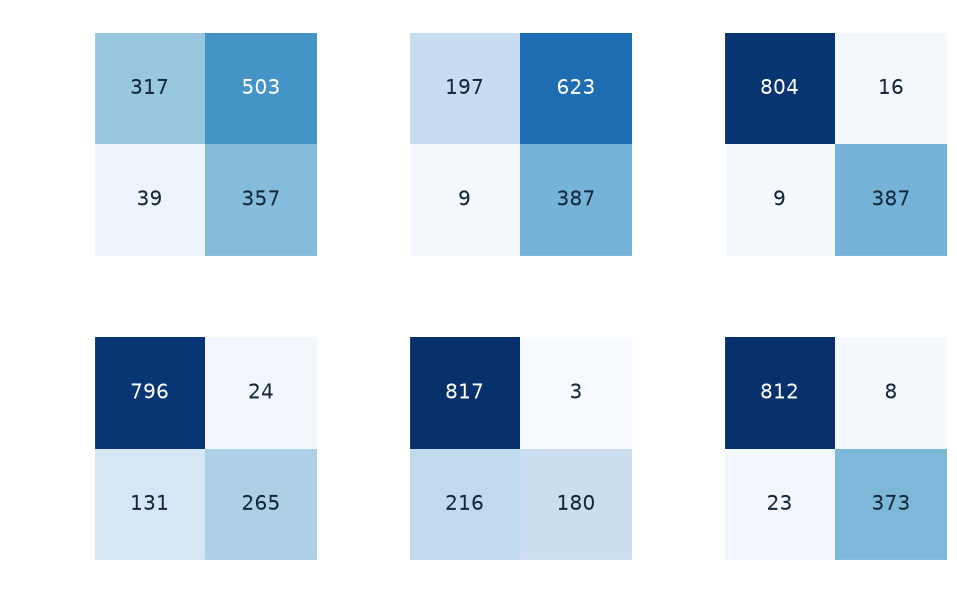

In [13]:
measures = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "fpr", "fnr"]
if tested:
    table(overall[["model", "mode", "threshold", "n_normal", "n_defect", *measures]])
    fig, axes = plt.subplots(2, len(tested), figsize=(3 * len(tested), 5.8),
                             squeeze=False, layout="constrained")
    largest = max(1, int(overall[["tn", "fp", "fn", "tp"]].max().max()))
    for col, m in enumerate(tested):
        for row, mode in enumerate(("default", "operating")):
            result = overall[(overall.model == m) & (overall["mode"] == mode)].iloc[0]
            cm = np.array([[result.tn, result.fp], [result.fn, result.tp]], dtype=int)
            ax = axes[row, col]
            ax.imshow(cm, vmin=0, vmax=largest, cmap="Blues")
            for (i, j), n in np.ndenumerate(cm):
                ax.text(j, i, str(n), ha="center", va="center", fontsize=14,
                        color="white" if n > largest * 0.52 else "#14283a")
            ax.set(xticks=[0, 1], xticklabels=["normal", "defect"], xlabel="Predicted",
                   yticks=[0, 1], yticklabels=["normal", "defect"], ylabel="Actual",
                   title=f"{m}  |  {mode}  {result.threshold:.4f}")
    plt.show()
else:
    print(command("evaluate"))

### 데이터 출처별 성능

표에는 정상·불량 원본 수와 함께 지표를 표시한다. 첫 설정 셀에서 `DETAIL_MODE`를 바꾸면 같은 저장 예측의 다른 임계값 결과를 확인할 수 있다. 각 모델의 `test/metrics.csv`에는 두 모드가 모두 들어 있다.

In [14]:
if tested:
    details = final[final["mode"] == DETAIL_MODE].copy()
    source_rows = details[details.scope.isin(["DeepPCB", "PKU", "VisA"])]
    columns = ["scope", "model", "n_normal", "n_defect", *measures]
    print("출처별 임계값 모드", DETAIL_MODE)
    table(source_rows[columns].sort_values(["scope", "model"]))
    missing = details[details.undefined.notna()]
    if len(missing):
        table(missing[["scope", "model", "n_normal", "n_defect", "undefined"]])

출처별 임계값 모드 operating


scope,model,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
DeepPCB,A,216,216,0.819,0.960,0.667,0.972,0.787,0.934,0.940,0.028,0.333
DeepPCB,B,216,216,0.910,0.984,0.833,0.986,0.902,0.993,0.993,0.014,0.167
DeepPCB,C,216,216,0.977,0.972,0.981,0.972,0.977,0.995,0.995,0.028,0.019
PKU,A,2,120,0.984,0.984,1.000,0.000,0.992,0.475,0.991,1.000,0.000
PKU,B,2,120,0.016,—,0.000,1.000,0.000,0.479,0.985,0.000,1.000
PKU,C,2,120,0.984,0.984,1.000,0.000,0.992,1.000,1.000,1.000,0.000
VisA,A,602,60,0.887,0.059,0.017,0.973,0.026,0.431,0.076,0.027,0.983
VisA,B,602,60,0.909,—,0.000,1.000,0.000,0.455,0.082,0.000,1.000
VisA,C,602,60,0.971,1.000,0.683,1.000,0.812,0.997,0.977,0.000,0.317


scope,model,n_normal,n_defect,undefined
VisA/pcb1,A,150,15,precision
VisA/pcb2,A,150,15,precision
VisA/pcb4,A,151,15,precision
PKU,B,2,120,precision
VisA,B,602,60,precision
VisA/pcb1,B,150,15,precision
VisA/pcb2,B,150,15,precision
VisA/pcb3,B,151,15,precision
VisA/pcb4,B,151,15,precision


### VisA PCB1~PCB4

원본 기준으로 PCB 종류별 결과를 나눈다. 불량 원본 수가 작을 때는 미검출 몇 건만으로도 recall이 크게 움직인다.

scope,model,n_normal,n_defect,accuracy,precision,recall,specificity,f1,roc_auc,pr_auc,fpr,fnr
VisA/pcb1,A,150,15,0.909,—,0.000,1.000,0.000,0.150,0.051,0.000,1.000
VisA/pcb1,B,150,15,0.909,—,0.000,1.000,0.000,0.299,0.131,0.000,1.000
VisA/pcb1,C,150,15,0.976,1.000,0.733,1.000,0.846,0.995,0.951,0.000,0.267
VisA/pcb2,A,150,15,0.909,—,0.000,1.000,0.000,0.359,0.072,0.000,1.000
VisA/pcb2,B,150,15,0.909,—,0.000,1.000,0.000,0.478,0.086,0.000,1.000
VisA/pcb2,C,150,15,0.976,1.000,0.733,1.000,0.846,1.000,0.996,0.000,0.267
VisA/pcb3,A,151,15,0.819,0.059,0.067,0.894,0.062,0.454,0.084,0.106,0.933
VisA/pcb3,B,151,15,0.910,—,0.000,1.000,0.000,0.434,0.073,0.000,1.000
VisA/pcb3,C,151,15,0.958,1.000,0.533,1.000,0.696,0.996,0.974,0.000,0.467
VisA/pcb4,A,151,15,0.910,—,0.000,1.000,0.000,0.714,0.210,0.000,1.000


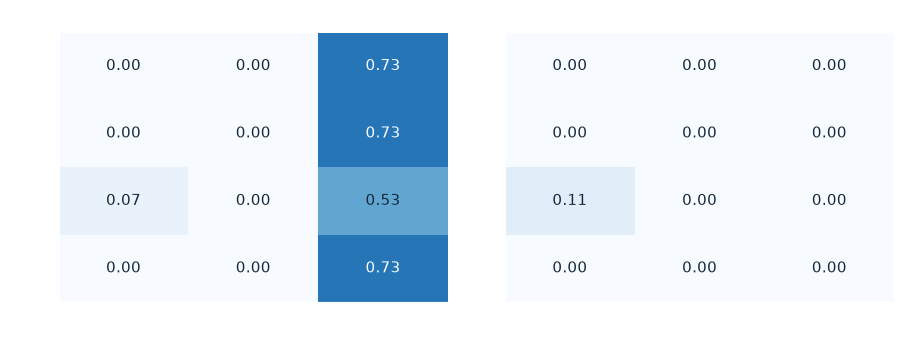

In [15]:
if tested:
    boards = details[details.scope.str.startswith("VisA/")]
    table(boards[columns].sort_values(["scope", "model"]))
    fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3), layout="constrained")
    for ax, metric, title in zip(axes, ["recall", "fpr"], ["Defect recall", "Normal FPR"]):
        matrix = boards.pivot(index="scope", columns="model", values=metric).reindex(columns=tested)
        values = matrix.to_numpy(float)
        ax.imshow(np.ma.masked_invalid(values), cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for (i, j), n in np.ndenumerate(values):
            ax.text(j, i, "—" if np.isnan(n) else f"{n:.2f}", ha="center", va="center",
                    color="white" if n > 0.55 else "#14283a")
        ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
               yticks=range(len(matrix)), yticklabels=[s.split("/")[-1] for s in matrix.index],
               xlabel="Training experiment", title=f"{title}   |   {DETAIL_MODE}")
    plt.show()

## 정상 오탐과 불량 미검출 사례

저장된 test 예측에서 정상 오탐은 불량 점수가 높은 순, 불량 미검출은 낮은 순으로 최대 세 장씩 표시한다. 청록색 창은 원본 점수를 결정한 입력 타일이다. 각 행의 원본 경로와 확률로 사례를 다시 확인할 수 있다.

사례 모델 및 임계값 모드 C operating


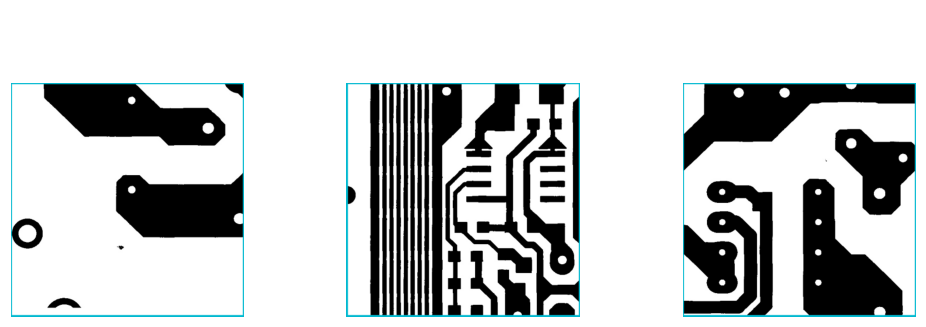

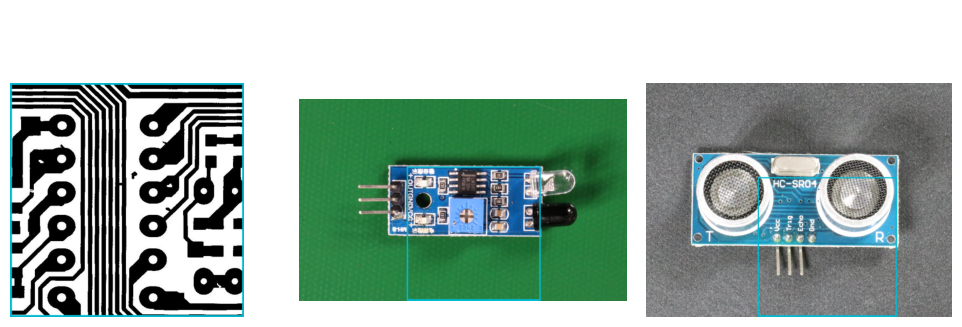

error,image_id,label,prob_defect,max_tile_id
False positive,DeepPCB/group13000/13000/13000035_temp.jpg,0,1.000,1028
False positive,DeepPCB/group13000/13000/13000005_temp.jpg,0,0.999,968
False positive,DeepPCB/group13000/13000/13000154_temp.jpg,0,0.998,1266
False negative,DeepPCB/group13000/13000/13000044_test.jpg,1,0.041,1047
False negative,VisA/pcb3/Data/Images/Anomaly/072.JPG,1,0.073,33656
False negative,VisA/pcb1/Data/Images/Anomaly/048.JPG,1,0.177,20282


In [16]:
if tested and has_data:
    model = ERROR_MODEL if ERROR_MODEL in tested else tested[-1]
    pred = read_frame(run_root / model / "test/predictions.csv")
    decision = pred["pred_" + DETAIL_MODE]
    cases = pd.concat([
        pred[(pred.label == 0) & (decision == 1)].nlargest(3, "prob_defect").assign(error="False positive"),
        pred[(pred.label == 1) & (decision == 0)].nsmallest(3, "prob_defect").assign(error="False negative")])
    print("사례 모델 및 임계값 모드", model, DETAIL_MODE)
    tile_lookup = tiles.set_index("tile_id")
    for error in ("False positive", "False negative"):
        examples = cases[cases.error == error]
        if examples.empty:
            print(error, "사례 0장")
            continue
        fig, axes = plt.subplots(1, len(examples), figsize=(3.2 * len(examples), 3),
                                 layout="constrained", squeeze=False)
        for ax, r in zip(axes[0], examples.itertuples()):
            path = Path(cfg["paths"][r.source]) / r.path
            if path.is_file():
                with Image.open(path) as raw:
                    image = raw.convert("RGB")
                tile = tile_lookup.loc[r.max_tile_id]
                box = (int(tile.x0), int(tile.y0), int(tile.x1)-1, int(tile.y1)-1)
                ImageDraw.Draw(image).rectangle(box, outline="#00bad1", width=max(4, image.width // 220))
                image.thumbnail((540, 420))
                ax.imshow(image)
            else:
                ax.text(0.5, 0.5, "Source image unavailable", ha="center")
            ax.set_title(f"{r.source} / {r.board}\nP(defect) {r.prob_defect:.4f}")
            ax.axis("off")
        fig.suptitle(f"{model}   |   {error}")
        plt.show()
    table(cases[["error", "image_id", "label", "prob_defect", "max_tile_id"]])
else:
    print("원본과 저장된 test 예측이 있어야 사례를 표시합니다.")

## EfficientNet-B0에서 학습 출처를 늘렸을 때의 변화

동일 원본 집합에서 출처를 추가했을 때의 차이를 퍼센트포인트로 계산한다. 운영 임계값 표에는 각 모델의 검증 단계에서 정한 값이 적용된다.

In [17]:
if tested:
    delta_rows = []
    for first, second in (("A", "B"), ("B", "C")):
        if first not in tested or second not in tested:
            continue
        for scope in ("all", "DeepPCB", "PKU", "VisA"):
            pair = details[details.scope == scope].set_index("model")
            delta_rows.append({"model change": f"{first} → {second}", "scope": scope,
                               "Δ recall (pp)": 100 * (pair.loc[second, "recall"] - pair.loc[first, "recall"]),
                               "Δ FPR (pp)": 100 * (pair.loc[second, "fpr"] - pair.loc[first, "fpr"])})
    if delta_rows:
        table(pd.DataFrame(delta_rows))
    for r in compact.itertuples():
        print(f"{r.model} · 불량 {r.n_defect}장 중 {r.fn}장 미검출, 정상 {r.n_normal}장 중 {r.fp}장 오탐.")
    if len(tested) > 1:
        current = source_rows[source_rows.model == tested[-1]].dropna(subset=["recall"])
        if len(current):
            r = current.loc[current.recall.idxmin()]
            display(Markdown(f"**{tested[-1]}의 출처별 최저 recall은 {r.scope}의 {r.recall:.1%}**였다. "
                             f"이 출처의 불량 {int(r.n_defect)}장 중 {int(r.fn)}장을 놓쳤다. "
                             "합산 점수에는 출처마다 다른 표본 수가 반영된다."))
    if has_data:
        pku_test = counts[(counts.source == "PKU") & (counts.split == "test")]
        if not pku_test.empty:
            n = int(pku_test.iloc[0].original_normal)
            print(f"PKU test 정상은 {n}장이다." + (f" 오탐 한 장이 FPR을 {100/n:.1f}%p 바꾼다." if n else " FPR은 정의되지 않는다."))

model change,scope,Δ recall (pp),Δ FPR (pp)
A → B,all,-21.465,-2.561
A → B,DeepPCB,16.667,-1.389
A → B,PKU,-100.000,-100.000
A → B,VisA,-1.667,-2.658
B → C,all,48.737,0.610
B → C,DeepPCB,14.815,1.389
B → C,PKU,100.000,100.000
B → C,VisA,68.333,0.000


A · 불량 396장 중 131장 미검출, 정상 820장 중 24장 오탐.
B · 불량 396장 중 216장 미검출, 정상 820장 중 3장 오탐.
C · 불량 396장 중 23장 미검출, 정상 820장 중 8장 오탐.


**C의 출처별 최저 recall은 VisA의 68.3%**였다. 이 출처의 불량 60장 중 19장을 놓쳤다. 합산 점수에는 출처마다 다른 표본 수가 반영된다.

PKU test 정상은 2장이다. 오탐 한 장이 FPR을 50.0%p 바꾼다.


## 실행 순서와 한계

1. 설정 파일의 데이터 경로를 확인하고 `python -m scr3.01_prepare`로 분할과 라벨 미리보기를 만든다.
2. `python -m scr3.02_train --experiments A B C`로 학습한다. validation에서 선택한 체크포인트·임계값·목표 달성 여부를 확인한다.
3. 조건을 확정한 뒤 `python -m scr3.03_evaluate --experiments A B C`를 한 번 실행하고 이 노트북을 위에서 아래로 실행한다.

DeepPCB와 PKU는 보드 그룹·템플릿 번호의 수가 작다. VisA는 각 종류 안에서 원본 이미지 ID 기준으로 나뉘므로 같은 PCB 제품 종류가 여러 분할에 등장한다. SHA-256은 파일 바이트의 중복을 검사하며 재인코딩한 유사 이미지를 식별하려면 별도 정보가 필요하다.

한 아키텍처 안에서 A·B·C의 학습 데이터 규모와 epoch당 업데이트 횟수는 달라진다. 같은 문자 조합의 두 아키텍처는 동일한 학습 원본과 타일을 사용한다. 결과는 설정과 seed가 하나인 비교다. 여러 타일 중 최댓값을 취하면 타일 수가 많은 원본의 오탐 가능성도 달라진다. 운영 목표는 validation에서 설정했으며 시험에서 관찰한 오탐·미검출 사례는 최종 성능을 설명하는 데 사용했다.

두 아키텍처에는 각각 torchvision에서 제공하는 사전학습 가중치를 사용했다. 비교 수치에는 그 초기 가중치와 모델 구조가 함께 영향을 준다. ResNet18의 test 결과는 이전 실험에서 확인한 결과이며 이번 비교는 같은 보드의 저장된 예측을 사용한다.

In [19]:
"""Evaluate a saved src2 ResNet18 on the Mendeley PCB-Defect positive-only cohort."""

from __future__ import annotations

import argparse
import math
import sys
from datetime import datetime, timezone
from itertools import islice
from pathlib import Path
from time import perf_counter

from src2.common import CLASSES, read_json, save_json, sha256, write_rows
from src2.mendeley_data import audit_dataset


DEFAULT_CONFIG = Path(__file__).with_name("mendeley_external_config.json")
LIMITATION = (
    "The dataset contains only defect images. This run measures defect recall on readable "
    "images and cannot establish how well the model separates normal and defective images."
)
UNDEFINED = {
    "TN": "There are no ground-truth normal images.",
    "FP": "There are no ground-truth normal images.",
    "specificity": "There are no ground-truth normal images.",
    "normal_false_positive_rate": "There are no ground-truth normal images.",
    "roc_auc": "Both ground-truth classes are required.",
}


class MissingCheckpointSettings(ValueError):
    def __init__(self, keys):
        self.keys = keys
        super().__init__(
            f"Checkpoint metadata missing: {', '.join(keys)}. "
            "Supply the original training values in checkpoint_metadata_overrides or a "
            "validation threshold and provenance via --threshold and --threshold-source."
        )


def settings_from_args():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", type=Path, default=DEFAULT_CONFIG)
    parser.add_argument("--image-dir", type=Path)
    parser.add_argument("--annotations", type=Path)
    parser.add_argument("--annotation-format", choices=("obb", "coco"))
    parser.add_argument("--checkpoint", type=Path)
    parser.add_argument("--threshold", type=float)
    parser.add_argument("--threshold-source", help="Original validation record for a manual threshold")
    parser.add_argument("--output-dir", type=Path)
    parser.add_argument("--device", choices=("auto", "cuda", "cpu"))
    parser.add_argument("--batch-size", type=int)
    parser.add_argument("--audit-only", action="store_true")
    args = parser.parse_args()
    config_path = args.config.resolve()
    settings = read_json(config_path)
    for key in ("image_dir", "annotations", "checkpoint", "output_dir"):
        value = getattr(args, key)
        settings[key] = value.resolve() if value is not None else (config_path.parent / settings[key]).resolve()
    for key in ("annotation_format", "threshold", "threshold_source", "device", "batch_size"):
        value = getattr(args, key)
        if value is not None:
            settings[key] = value
    settings["config_path"] = config_path
    settings["audit_only"] = args.audit_only
    if settings["annotation_format"] not in ("obb", "coco"):
        raise ValueError("annotation_format must be obb or coco")
    if settings["device"] not in ("auto", "cuda", "cpu"):
        raise ValueError("device must be auto, cuda or cpu")
    return settings


def checkpoint_settings(saved, config):
    overrides = config.get("checkpoint_metadata_overrides", {})
    if not isinstance(overrides, dict):
        raise ValueError("checkpoint_metadata_overrides must be an object with dotted keys")
    applied = {}
    missing = []

    def read_setting(name, optional=False):
        value = saved
        for key in name.split("."):
            value = value.get(key) if isinstance(value, dict) else None
        if value is not None:
            return value
        if name in overrides and overrides[name] is not None:
            applied[name] = overrides[name]
            return applied[name]
        if not optional:
            missing.append(name)
        return None

    training = {
        key: read_setting(f"training.{key}")
        for key in ("model", "image_size", "preprocessing")
    }
    if training["preprocessing"] == "binary":
        training["binary_cutoff"] = read_setting("training.binary_cutoff")
    tiling = {key: read_setting(f"tiling.{key}") for key in ("size", "overlap")}
    pooling = read_setting("pooling")
    classes = read_setting("classes")
    calibration = saved.get("calibration") or {}
    threshold = config.get("threshold")
    provenance = config.get("threshold_source")
    if threshold is None:
        threshold = saved.get("threshold")
        if threshold is None:
            missing.append("threshold")
        if not str(calibration.get("selected_on", "")).startswith("validation"):
            missing.append("calibration.selected_on")
        calibrated_threshold = calibration.get("threshold")
        if calibrated_threshold is not None and calibrated_threshold != threshold:
            raise ValueError("Checkpoint threshold disagrees with its validation calibration")
        provenance = "checkpoint calibration (" + str(calibration.get("selected_on")) + ")"
    elif not isinstance(provenance, str) or not provenance.strip():
        raise ValueError("A manual threshold requires --threshold-source identifying the existing validation record")
    if missing:
        raise MissingCheckpointSettings(missing)

    if training["model"] != "efficientnet_b0" or classes != CLASSES or pooling != "max":
        raise ValueError("Expected src3 EfficientNet-B0, classes 0=normal/1=defect and max image pooling")
    if type(training["image_size"]) is not int or training["image_size"] <= 0:
        raise ValueError("Checkpoint training.image_size must be a positive integer")
    if training["preprocessing"] not in ("rgb", "binary"):
        raise ValueError("Unknown checkpoint preprocessing mode")
    if training["preprocessing"] == "binary" and (
        type(training["binary_cutoff"]) is not int or not 0 <= training["binary_cutoff"] <= 255
    ):
        raise ValueError("Checkpoint binary_cutoff must be an integer in [0, 255]")
    if any(type(value) is not int for value in tiling.values()) or not 0 <= tiling["overlap"] < tiling["size"]:
        raise ValueError("Require integer tile pixel counts with 0 <= overlap < size")
    if type(threshold) not in (float, int) or not math.isfinite(threshold) or not 0 <= threshold <= 1:
        raise ValueError("The validation threshold must be a finite number in [0, 1]")

    batch_size = config.get("batch_size")
    if batch_size is None:
        batch_size = (saved.get("training") or {}).get("batch_size", 16)
    if type(batch_size) is not int or batch_size <= 0:
        raise ValueError("Use a positive integer for --batch-size")
    training["batch_size"] = batch_size
    return training, tiling, float(threshold), provenance, applied


def load_model(config, summary):
    import torch

    from src2.model import device_for, network

    checkpoint = config["checkpoint"]
    summary["checkpoint"]["sha256"] = sha256(checkpoint)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    training, tiling, threshold, provenance, applied = checkpoint_settings(saved, config)
    summary["checkpoint"].update(
        architecture=training["model"],
        experiment=saved.get("experiment"),
        best_epoch=saved.get("best_epoch"),
        protocol_id=saved.get("protocol_id"),
        metadata_overrides_applied=applied,
    )
    summary["preprocessing"] = {
        "decode": "Pillow convert RGB",
        "resize": "crop native tile then resize with Pillow bilinear",
        "input_size": [training["image_size"]] * 2,
        "tensor_layout": "NCHW",
        "scale": "uint8 / 255",
        "mode": training["preprocessing"],
        "binary_cutoff": training.get("binary_cutoff"),
        "normalize_mean": [0.485, 0.456, 0.406],
        "normalize_std": [0.229, 0.224, 0.225],
        "augmentation": False,
        "implementation": "src2.inputs.rgb_tile and collate, src2.model.input_batch and batch_scores",
    }
    summary["tiling"] = {
        **tiling,
        "stride": tiling["size"] - tiling["overlap"],
        "edge_policy": "src2.tiles.windows grid: anchor final tile to each edge, clip dimensions smaller than tile size",
        "coordinates": "original pixels, half-open (x0, y0, x1, y1)",
    }
    summary["scoring"] = {
        "tile_score": "float32 softmax(logits)[1]",
        "image_score": "max of all tile scores",
        "threshold": threshold,
        "threshold_source": provenance,
        "validation_calibration": saved.get("calibration"),
        "positive_if": "score >= threshold",
    }
    device = device_for(config["device"])
    summary["device"].update(
        used=str(device), torch_version=str(torch.__version__), batch_size=training["batch_size"]
    )
    if device.type == "cuda":
        summary["device"]["name"] = torch.cuda.get_device_name(device)
    model = network(training["model"], pretrained=False)
    model.load_state_dict(saved["state_dict"], strict=True)
    model = model.to(device, memory_format=torch.channels_last).eval()
    summary["checkpoint"]["strict_state_dict_loaded"] = True
    return model, device, training, tiling, threshold


def predict_images(config, images, model, device, training, tiling, threshold):
    from PIL import Image

    from src2.inputs import collate, rgb_tile
    from src2.model import batch_scores
    from src2.tiles import windows

    image_rows = []
    tile_rows = []
    for relative, info in images.items():
        if info["status"] != "ok":
            continue
        path = config["image_dir"] / relative
        if sha256(path) != info["sha256"]:
            raise ValueError(f"Image changed after audit: {path}")
        with Image.open(path) as raw:
            image = raw.convert("RGB")
        grid = windows(*image.size, "grid", tiling)
        image_tiles = []
        while True:
            boxes = list(islice(grid, training["batch_size"]))
            if not boxes:
                break
            tiles = [(rgb_tile(image, box, training["image_size"]), 0) for box in boxes]
            batch, _ = collate(tiles)
            scores = batch_scores(model, batch, device, training)
            if getattr(scores, "shape", None) != (len(boxes),):
                raise ValueError(f"Expected one defect probability per tile for {relative}")
            for box, score in zip(boxes, scores):
                score = float(score)
                if not 0 <= score <= 1:
                    raise ValueError(f"Invalid tile probability for {relative}: {score}")
                image_tiles.append({
                    "image_path": relative, "tile_number": len(image_tiles) + 1,
                    "x0": box[0], "y0": box[1], "x1": box[2], "y1": box[3],
                    "prob_defect": score, "prob_normal": 1 - score,
                    "prediction": CLASSES[str(int(score >= threshold))],
                })
        if not image_tiles:
            raise ValueError(f"No tiles produced for {relative}")
        best = max(image_tiles, key=lambda row: row["prob_defect"])
        score = best["prob_defect"]
        image_rows.append({
            "image_path": relative, "width": info["width"], "height": info["height"],
            "tile_count": len(image_tiles), "best_tile_number": best["tile_number"],
            "max_prob_defect": score, "threshold": threshold,
            "prediction": best["prediction"], "ground_truth": "defect",
            "annotation_linked": info["annotation_linked"],
            "defect_box_count": info["defect_box_count"],
            "original_classes": info["original_classes"],
        })
        tile_rows.extend(image_tiles)
    return image_rows, tile_rows


def evaluate(config, output):
    start = perf_counter()
    summary = {
        "started_at_utc": datetime.now(timezone.utc).isoformat(),
        "status": "started",
        "config_path": str(config["config_path"]),
        "checkpoint": {"path": str(config["checkpoint"]), "strict_state_dict_loaded": False},
        "requested_threshold": config.get("threshold"),
        "requested_threshold_source": config.get("threshold_source"),
        "device": {"requested": config["device"]},
        "limitation": LIMITATION,
        "unavailable_metrics": UNDEFINED,
    }
    try:
        images, boxes, audit = audit_dataset(
            config["image_dir"], config["annotations"], config["annotation_format"],
            config.get("obb_classes"), output,
        )
        summary["audit"] = audit
        save_json(output / "audit.json", audit)
        observed = audit["observed"]
        print(f"Audit: {observed['image_files']} image files, "
              f"{observed['annotation_rows']} annotation rows, "
              f"{audit['readable_images']} readable images")
        differences = audit["difference_from_published_v2"]
        if any(value != 0 for value in differences.values()):
            print(f"Difference from published v2 counts: {differences}", file=sys.stderr)
        if audit["issue_counts"]:
            print(f"Audit issues: {audit['issue_counts']}. See audit_issues.csv.", file=sys.stderr)
        if config["audit_only"]:
            summary["status"] = "audit_only"
            return
        if not audit["readable_images"]:
            raise ValueError("No readable images. See audit_images.csv and audit_issues.csv.")

        model, device, training, tiling, threshold = load_model(config, summary)
        image_rows, tile_rows = predict_images(config, images, model, device, training, tiling, threshold)
        write_rows(output / "image_predictions.csv", image_rows)
        write_rows(output / "tile_predictions.csv", tile_rows)

        import matplotlib
        import numpy as np

        matplotlib.use("Agg")
        from src2.mendeley_figures import save_figures

        tp = sum(row["prediction"] == "defect" for row in image_rows)
        total = len(image_rows)
        scores = [row["max_prob_defect"] for row in image_rows]
        summary["metrics"] = {
            "total_image_files": len(images), "evaluated_defect_images": total,
            "unreadable_excluded": len(images) - total,
            "detected_defect_images": tp, "missed_defect_images": total - tp,
            "confusion_counts": {"TP": tp, "FN": total - tp},
            "defect_recall": tp / total, "defect_miss_rate": (total - tp) / total,
            "always_defect_baseline_recall": 1.0,
            "recall_gap_vs_baseline": tp / total - 1.0,
            "tile_count": len(tile_rows),
            "score_distribution": {
                str(key): float(value)
                for key, value in zip(
                    ("min", "p25", "median", "p75", "max"), np.quantile(scores, [0, .25, .5, .75, 1])
                )
            },
        }
        summary["figures"] = save_figures(output, config["image_dir"], image_rows, tile_rows, boxes, threshold)
        summary["status"] = "completed"
    except Exception as error:
        summary["status"] = "failed"
        summary["error"] = f"{type(error).__name__}: {error}"
        if isinstance(error, MissingCheckpointSettings):
            summary["missing_checkpoint_settings"] = error.keys
        raise
    finally:
        summary["runtime_seconds"] = round(perf_counter() - start, 3)
        save_json(output / "summary.json", summary)


def main():
    from filelock import FileLock

    try:
        config = settings_from_args()
        output = config["output_dir"]
        annotation_path = config["annotations"]
        protected = (
            config["image_dir"], annotation_path.parent if annotation_path.suffix.lower() in {".json", ".txt"}
            else annotation_path,
            config["checkpoint"].parent,
            Path(__file__).resolve().parent.parent / "out_data",
        )
        if any(output.is_relative_to(path) for path in protected):
            raise ValueError("Use an output directory outside the data folders and checkpoint directory")
        output.parent.mkdir(parents=True, exist_ok=True)
        with FileLock(str(output) + ".lock", timeout=0):
            output.mkdir(exist_ok=True)
            if any(output.iterdir()):
                raise ValueError(f"Output directory already contains files. Choose a new --output-dir: {output}")
            evaluate(config, output)
        print(f"Saved artifacts to {output}")
    except Exception as error:
        print(f"Mendeley external evaluation: {error}", file=sys.stderr)
        return 1
    return 0


if __name__ == "__main__":
    raise SystemExit(main())



NameError: name '__file__' is not defined